# Bayesian Linear Regression

Ordinary linear regression (`01_linear_regression`) returns **one** weight vector and predictions with no sense of how sure it is. Bayesian linear regression keeps a whole **distribution** over the weights, so every prediction comes with an error bar that is honest about both noise in the data and ignorance about the model.

## How it works

Assume Gaussians on both sides:

- noise: `y = Xw + ε`, `ε ~ N(0, 1/α)` (`α` = noise precision)
- prior: `w ~ N(0, (1/λ)·I)` (`λ` = weight precision)

Then the **posterior** over `w` is Gaussian in closed form:

```
S = (λI + α XᵀX)⁻¹        posterior covariance
m = α S Xᵀy                posterior mean   (= ridge regression with strength λ/α)
```

and the **prediction** at `x` is Gaussian too:

```
mean = x·m        variance = 1/α  +  xᵀ S x
                            └ noise   └ uncertainty about the weights — grows away from the training data
```

### No hand-tuned regularization

`α` and `λ` are learned by maximising the **marginal likelihood** (evidence) with MacKay's fixed-point updates:

```
γ = Σ αeᵢ / (λ + αeᵢ)        (effective number of well-determined weights; eᵢ = eigenvalues of XᵀX)
λ ← γ / mᵀm
α ← (N − γ) / ‖y − Xm‖²
```

Repeat until stable. Too many features and too little data? The evidence shrinks the useless weights automatically — no cross-validation. Names `alpha_`, `lambda_` match scikit-learn's `BayesianRidge`, and with its priors set to zero the results are identical (the demo checks it).

Linear in the *weights* only: feed it polynomial or other basis features to fit curves (demo does a cubic and prints widening intervals at `x = 0.9, 1.5, 3`).

`ponytail:` one global weight precision `λ`; per-feature precisions (Automatic Relevance Determination) is the upgrade for sparse problems.

## Usage

```python
# (the class is defined in the Implementation section below)

model = BayesianLinearRegression().fit(X, y)
mean, std = model.predict(X_new, return_std=True)   # std includes the noise
model.coef_, model.sigma_                           # posterior mean and covariance of the weights
model.alpha_, model.lambda_                         # learned precisions
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class BayesianLinearRegression:
    """Linear regression that returns a DISTRIBUTION over weights, not one point estimate.

    Model:  y = X w + noise,   noise ~ N(0, 1/alpha),   w ~ N(0, 1/lambda * I)
    (alpha = noise precision, lambda = weight precision; same names as scikit-learn's BayesianRidge.)

    With those Gaussians the posterior over w is Gaussian in closed form:
        S = (lambda I + alpha X'X)^-1          (posterior covariance)
        m = alpha S X'y                        (posterior mean -- equals ridge regression)
    and the prediction at x is Gaussian too:
        mean = x.m          variance = 1/alpha + x' S x
    i.e. noise in the data + uncertainty about the weights (which grows away from the training data).

    alpha and lambda are NOT hand-tuned: they are learned by maximising the marginal likelihood
    (evidence) with MacKay's fixed-point updates (Bishop, PRML 3.5). Overfitting is controlled
    automatically -- no cross-validation needed.

    ponytail: fixed-point iteration with a flat (improper-ish) prior on alpha, lambda; uses the SVD of X
    once so every iteration is O(d)."""

    def __init__(self, max_iter=300, tol=1e-3, alpha_init=None, lambda_init=1.0, fit_intercept=True):
        self.max_iter = max_iter
        self.tol = tol
        self.alpha_init = alpha_init
        self.lambda_init = lambda_init
        self.fit_intercept = fit_intercept

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.x_mean_ = X.mean(axis=0) if self.fit_intercept else np.zeros(d)
        self.y_mean_ = y.mean() if self.fit_intercept else 0.0
        Xc, yc = X - self.x_mean_, y - self.y_mean_

        U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
        eig = s ** 2                            # eigenvalues of X'X
        Uty = U.T @ yc
        resid_outside = yc @ yc - Uty @ Uty     # part of y no linear combination of X can reach

        alpha = self.alpha_init or 1.0 / (np.var(yc) + 1e-12)
        lam = self.lambda_init
        for _ in range(self.max_iter):
            m = Vt.T @ (alpha * s / (lam + alpha * eig) * Uty)
            gamma = (alpha * eig / (lam + alpha * eig)).sum()  # effective number of well-determined weights
            rss = ((yc - Xc @ m) ** 2).sum()
            lam_new = gamma / max(m @ m, 1e-12)
            alpha_new = (n - gamma) / max(rss, 1e-12)
            done = abs(lam_new - lam) < self.tol * lam and abs(alpha_new - alpha) < self.tol * alpha
            lam, alpha = lam_new, alpha_new
            if done:
                break

        self.alpha_, self.lambda_ = alpha, lam
        self.sigma_ = Vt.T @ np.diag(1.0 / (lam + alpha * eig)) @ Vt   # posterior covariance of w
        self.coef_ = alpha * self.sigma_ @ Xc.T @ yc                   # posterior mean of w
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.coef_
        return self

    def predict(self, X, return_std=False):
        X = np.asarray(X, dtype=float)
        mean = X @ self.coef_ + self.intercept_
        if not return_std:
            return mean
        Xc = X - self.x_mean_
        var = 1.0 / self.alpha_ + ((Xc @ self.sigma_) * Xc).sum(axis=1)
        return mean, np.sqrt(var)

## See it work

### 1. A fit with honest error bars

Cubic polynomial features, 25 noisy points. The band is the predictive ±2σ: it includes the noise level **and** the uncertainty about the weights, so it fans out where there is no data (left of the first point and right of the last).

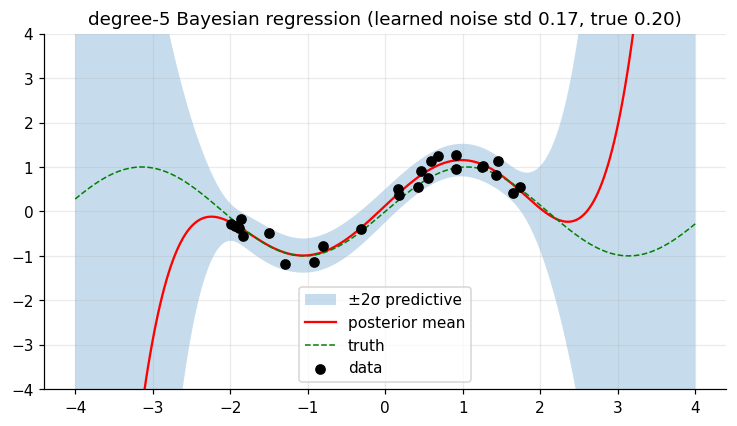

In [3]:
rng = np.random.default_rng(0)
x = rng.uniform(-2, 2, 25); y = np.sin(1.5 * x) + rng.normal(scale=0.2, size=25)
poly = lambda v, d=5: np.column_stack([np.asarray(v) ** p for p in range(1, d + 1)])
m = BayesianLinearRegression().fit(poly(x), y)
xs = np.linspace(-4, 4, 300); mean, std = m.predict(poly(xs), return_std=True)
plt.figure(figsize=(8, 4.2)); plt.fill_between(xs, mean - 2 * std, mean + 2 * std, alpha=0.25, label="±2σ predictive")
plt.plot(xs, mean, "r", label="posterior mean"); plt.plot(xs, np.sin(1.5 * xs), "g--", lw=1, label="truth"); plt.scatter(x, y, c="k", zorder=3, label="data")
plt.ylim(-4, 4); plt.legend(); plt.title(f"degree-5 Bayesian regression (learned noise std {1 / np.sqrt(m.alpha_):.2f}, true 0.20)"); plt.show()

### 2. Sampling functions from the posterior

The posterior over the weights is a Gaussian (`coef_`, `sigma_`). Each draw is one plausible curve consistent with the data: they agree near the data and disagree wildly outside it. The spread of the curves *is* the model's uncertainty.

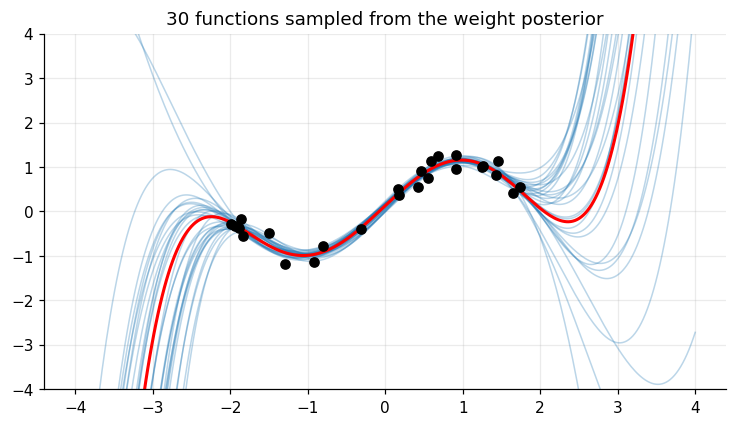

In [4]:
W = rng.multivariate_normal(m.coef_, m.sigma_, size=30)
curves = (poly(xs) - m.x_mean_) @ W.T + m.y_mean_
plt.figure(figsize=(8, 4.2)); plt.plot(xs, curves, color="C0", alpha=0.3, lw=1); plt.plot(xs, mean, "r", lw=2); plt.scatter(x, y, c="k", zorder=3)
plt.ylim(-4, 4); plt.title("30 functions sampled from the weight posterior"); plt.show()

### 3. Automatic regularisation: no overfitting with a flexible model

Ordinary least squares with a degree-12 polynomial on these 25 points wiggles through the noise. The Bayesian model, with the same 12 features, learns a weight precision `λ` from the data (the evidence) and shrinks the useless high-order terms, so it stays smooth across the data without cross-validation (and the wide band outside the data honestly admits it does not know).

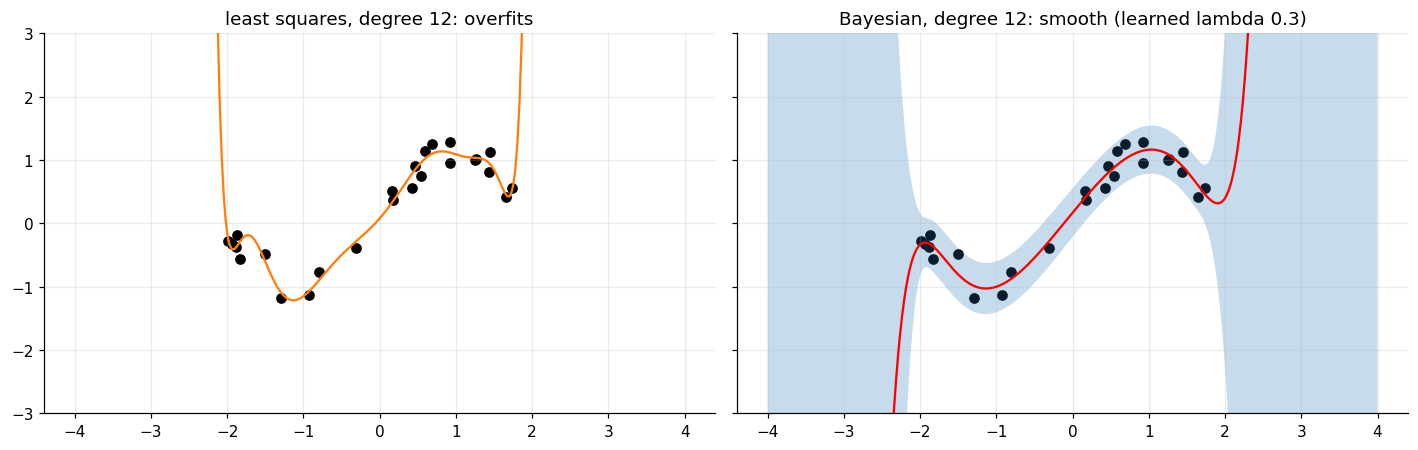

In [5]:
P = poly(x, 12); Pt = poly(xs, 12)
scale = np.abs(P).max(axis=0); P, Pt = P / scale, Pt / scale                     # keep the monomials on a comparable scale
ols = np.linalg.lstsq(np.c_[np.ones(len(P)), P], y, rcond=None)[0]
bayes = BayesianLinearRegression().fit(P, y); bm, bs = bayes.predict(Pt, return_std=True)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
a.scatter(x, y, c="k"); a.plot(xs, np.c_[np.ones(len(Pt)), Pt] @ ols, "C1"); a.set_title("least squares, degree 12: overfits"); a.set_ylim(-3, 3)
b.scatter(x, y, c="k"); b.plot(xs, bm, "r"); b.fill_between(xs, bm - 2 * bs, bm + 2 * bs, alpha=0.25); b.set_title(f"Bayesian, degree 12: smooth (learned lambda {bayes.lambda_:.2g})")
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.linear_model import BayesianRidge

zero_prior = dict(alpha_1=0, alpha_2=0, lambda_1=0, lambda_2=0, tol=1e-10, max_iter=1000)  # plain evidence maximisation

# 1) same learned precisions and weights as scikit-learn's BayesianRidge
rng = np.random.default_rng(0)
X = rng.normal(size=(150, 6))
w = np.array([3.0, 0.0, -2.0, 0.0, 0.5, 0.0])
y = X @ w + 1.0 + rng.normal(scale=0.5, size=150)

ours = BayesianLinearRegression().fit(X, y)
theirs = BayesianRidge(**zero_prior).fit(X, y)
print("noise precision alpha: ours=%.4f sklearn=%.4f" % (ours.alpha_, theirs.alpha_))
print("weight precision lambda: ours=%.4f sklearn=%.4f" % (ours.lambda_, theirs.lambda_))
assert np.isclose(ours.alpha_, theirs.alpha_, rtol=1e-4) and np.isclose(ours.lambda_, theirs.lambda_, rtol=1e-4)
assert np.allclose(ours.coef_, theirs.coef_, atol=1e-6) and np.isclose(ours.intercept_, theirs.intercept_, atol=1e-6)
print("coefficients:", ours.coef_.round(3), "(true", w, ")")

# 2) predictive standard deviation (compared on centred data: sklearn ignores the centring when computing it)
Xc, yc = X - X.mean(0), y - y.mean()
ours0 = BayesianLinearRegression(fit_intercept=False).fit(Xc, yc)
theirs0 = BayesianRidge(fit_intercept=False, **zero_prior).fit(Xc, yc)
assert np.allclose(ours0.predict(Xc, return_std=True)[1], theirs0.predict(Xc, return_std=True)[1], atol=1e-6)
print("predictive std matches sklearn")

# 3) the point of being Bayesian: honest error bars that widen away from the data (cubic fit)
x = rng.uniform(-1, 1, size=40)
t = np.sin(2.5 * x) + rng.normal(scale=0.1, size=40)
poly = lambda v: np.column_stack([np.asarray(v) ** p for p in (1, 2, 3)])
model = BayesianLinearRegression().fit(poly(x), t)
for point in (0.0, 0.9, 1.5, 3.0):
    mean, std = model.predict(poly([point]), return_std=True)
    print("x=%.1f  prediction %6.2f +/- %.2f   (truth %5.2f)" % (point, mean[0], 1.96 * std[0], np.sin(2.5 * point)))

noise precision alpha: ours=4.4051 sklearn=4.4051
weight precision lambda: ours=0.4493 sklearn=0.4493
coefficients: [ 3.002 -0.018 -2.036 -0.017  0.431  0.041] (true [ 3.   0.  -2.   0.   0.5  0. ] )
predictive std matches sklearn
x=0.0  prediction   0.05 +/- 0.18   (truth  0.00)
x=0.9  prediction   0.80 +/- 0.21   (truth  0.78)
x=1.5  prediction  -2.65 +/- 0.80   (truth -0.57)
x=3.0  prediction -42.35 +/- 6.82   (truth  0.94)


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def _data(seed=0, n=200, noise=0.5):
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 4))
    w = np.array([2.0, -1.0, 0.0, 0.5])
    return X, X @ w + 3.0 + rng.normal(scale=noise, size=n), w


def test_posterior_matches_textbook_formulas_and_ridge():
    X, y, _ = _data()
    model = BayesianLinearRegression().fit(X, y)
    Xc, yc = X - X.mean(0), y - y.mean()
    a, l = model.alpha_, model.lambda_
    S = np.linalg.inv(l * np.eye(4) + a * Xc.T @ Xc)
    assert np.allclose(model.sigma_, S)
    assert np.allclose(model.coef_, a * S @ Xc.T @ yc)
    ridge = np.linalg.solve(Xc.T @ Xc + (l / a) * np.eye(4), Xc.T @ yc)  # posterior mean == ridge with strength lambda/alpha
    assert np.allclose(model.coef_, ridge)


def test_learns_noise_level_and_weights():
    X, y, w = _data(n=2000, noise=0.5)
    model = BayesianLinearRegression().fit(X, y)
    assert abs(1 / np.sqrt(model.alpha_) - 0.5) < 0.03       # recovered noise std
    assert np.allclose(model.coef_, w, atol=0.05) and abs(model.intercept_ - 3.0) < 0.05


def test_uncertainty_grows_away_from_the_data():
    rng = np.random.default_rng(1)
    x = rng.uniform(-1, 1, size=(30, 1))
    y = 2 * x[:, 0] + rng.normal(scale=0.2, size=30)
    model = BayesianLinearRegression().fit(x, y)
    _, std = model.predict([[0.0], [1.0], [10.0], [100.0]], return_std=True)
    assert std[0] < std[1] < std[2] < std[3]
    assert std[0] > 1 / np.sqrt(model.alpha_) - 1e-9           # never below the noise floor


def test_interval_coverage_is_calibrated():
    X, y, _ = _data(seed=2, n=300)
    Xt, yt, _ = _data(seed=3, n=3000)
    mean, std = BayesianLinearRegression().fit(X, y).predict(Xt, return_std=True)
    coverage = (np.abs(yt - mean) < 1.96 * std).mean()
    assert abs(coverage - 0.95) < 0.02


def test_irrelevant_features_are_shrunk_hard_with_few_samples():
    rng = np.random.default_rng(4)
    X = rng.normal(size=(40, 30))                              # 30 features, only the first matters
    y = 3 * X[:, 0] + rng.normal(scale=0.3, size=40)
    coef = BayesianLinearRegression().fit(X, y).coef_
    assert abs(coef[0] - 3) < 0.3 and np.abs(coef[1:]).max() < 0.3

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_posterior_matches_textbook_formulas_and_ridge
PASS test_learns_noise_level_and_weights
PASS test_uncertainty_grows_away_from_the_data
PASS test_interval_coverage_is_calibrated
PASS test_irrelevant_features_are_shrunk_hard_with_few_samples

all 5 tests passed


## Takeaways

- **Use it** when you need uncertainty with a linear model, have little data, or want regularisation set automatically (the evidence maximisation replaces cross-validation). Equivalent to ridge regression whose strength `λ/α` is learned.
- **Posterior:** `S = (λI + αXᵀX)⁻¹`, `m = αSXᵀy`; prediction `N(x·m, 1/α + xᵀSx)`. The evidence updates are `λ ← γ/mᵀm`, `α ← (N − γ)/‖y − Xm‖²` with `γ = Σ αeᵢ/(λ + αeᵢ)` the effective number of parameters.
- **Pitfalls:** assumes Gaussian noise and one shared weight prior; predictive intervals are only as good as these assumptions.
- **Interview line:** *"Gaussian prior on weights plus Gaussian noise gives a Gaussian posterior in closed form; the predictive variance is noise plus weight uncertainty, which grows away from the data."*